# Agentic Reasoning for Data Science: Full Study (rerun with the fixed Reviewer)
End-to-end run of the cyclic LangGraph pipeline (Planner, EDA Analyst, ML Architect, Quality Reviewer, Report Writer) on three datasets, compared with a single agent and AutoGluon, on clean and corrupted data.

**What is different from the first version**
- Every system gets the same split, features and models. Corruption is seeded and applied to training data only.
- Results are reported on the training set **and** the held-out test set, so overfitting is visible.
- **F1 is reported everywhere**, next to MCC and balanced accuracy, plus an always-positive baseline. F1 alone is unsafe because predicting "positive" for everyone already scores a high F1 on these datasets. Models are chosen by cross-validated MCC on training data only.
- The Reviewer was rebuilt. It drops impossible values, flags leaked features (including a score-jump check) and only removes suspected wrong labels when a leak-free cross-validation test proves it helps. Otherwise it reports them.
- All tables and charts are built from the saved CSV files.

## Step 1: Setup and configuration

In [24]:
import os, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import agentic_bench as ab, agentic_viz as viz

# ---- edit these paths ----
HEART_CSV  = os.path.expanduser("~/Downloads/archive/heart_disease_cleveland.csv")
NYC_PARQUET = os.path.expanduser("~/Downloads/yellow_tripdata_2024-01.parquet")
AMAZON_CSV = "data/amazon_beauty_50k.csv"     # columns: rating,text,verified,title,helpful_vote

# ---- run size ----
SEEDS = {"Heart_Disease": range(10), "Amazon_Reviews": range(5), "NYC_Taxi": range(5)}
USE_AUTOGLUON = False      # True adds AutoGluon (60 s per fit, slow)
USE_LLM = False            # True needs `ollama serve` and llama3.2; writes the plan and report text
QUICK = os.environ.get("QUICK") == "1"     # tiny run to check everything works
if QUICK:
    SEEDS = {k: range(2) for k in SEEDS}
os.makedirs("outputs", exist_ok=True)

llm = None
if USE_LLM:
    from langchain_ollama import OllamaLLM
    llm = OllamaLLM(model="llama3.2")
    print("Ollama connected")

## Step 2: Load the three datasets

In [25]:
%pip install vaderSentiment pyarrow shap seaborn

Note: you may need to restart the kernel to use updated packages.


In [26]:
df_heart, t_heart = ab.load_heart(HEART_CSV)

def load_amazon_csv(path, n=5000, seed=42):
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    d = pd.read_csv(path).dropna(subset=["text", "title", "rating"])
    d = d[(d.text.str.len() > 0)].sample(n=min(n, len(d)), random_state=seed).reset_index(drop=True)
    sia = SentimentIntensityAnalyzer()
    out = pd.DataFrame({
        "text_length": d.text.str.len(), "title_length": d.title.astype(str).str.len(),
        "word_count": d.text.str.split().str.len(), "exclaim_count": d.text.str.count("!"),
        "upper_ratio": d.text.apply(lambda s: sum(c.isupper() for c in s) / max(len(s), 1)),
        "vader_text": d.text.apply(lambda s: sia.polarity_scores(s)["compound"]),
        "vader_title": d.title.astype(str).apply(lambda s: sia.polarity_scores(s)["compound"]),
        "helpful_vote": d.helpful_vote, "verified": d.verified.astype(int),
        "sentiment": (d.rating >= 4).astype(int)})
    return out, "sentiment"

df_nyc, t_nyc = ab.load_nyc(NYC_PARQUET, n=2000 if QUICK else 5000)
df_amz, t_amz = load_amazon_csv(AMAZON_CSV, n=1500 if QUICK else 5000)
DATA = {"Heart_Disease": (df_heart, t_heart), "NYC_Taxi": (df_nyc, t_nyc), "Amazon_Reviews": (df_amz, t_amz)}
for k, (d, t) in DATA.items():
    print(f"{k}: {d.shape}, positive rate {d[t].mean():.2f}, missing cells {int(d.isna().sum().sum())}")

Heart_Disease: (303, 14), positive rate 0.46, missing cells 6
NYC_Taxi: (5000, 8), positive rate 0.80, missing cells 0
Amazon_Reviews: (5000, 10), positive rate 0.74, missing cells 0


## Step 3: Exploratory data analysis

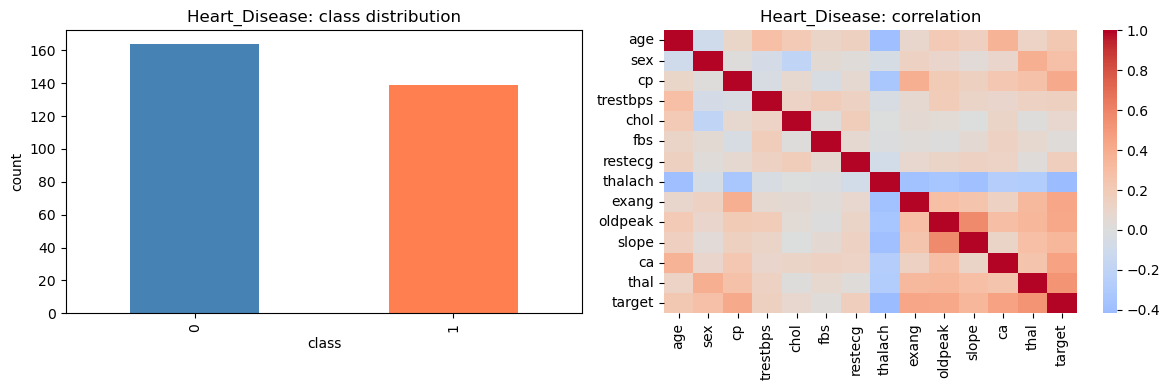

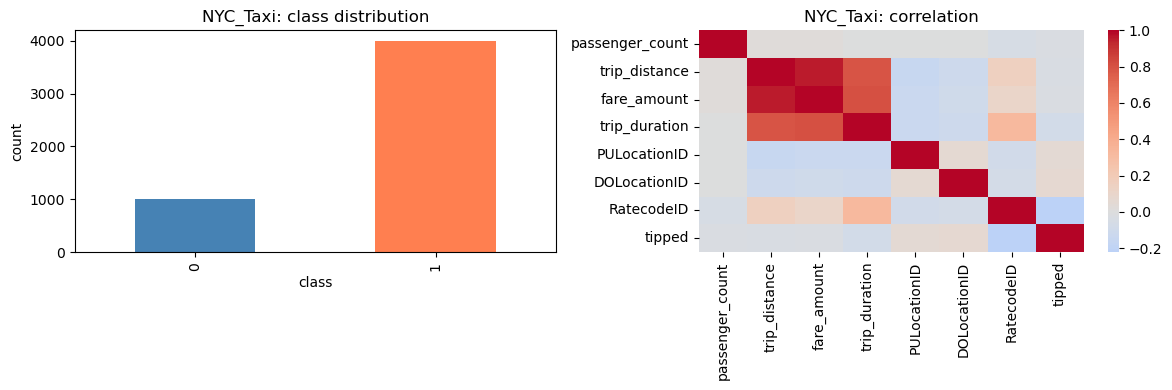

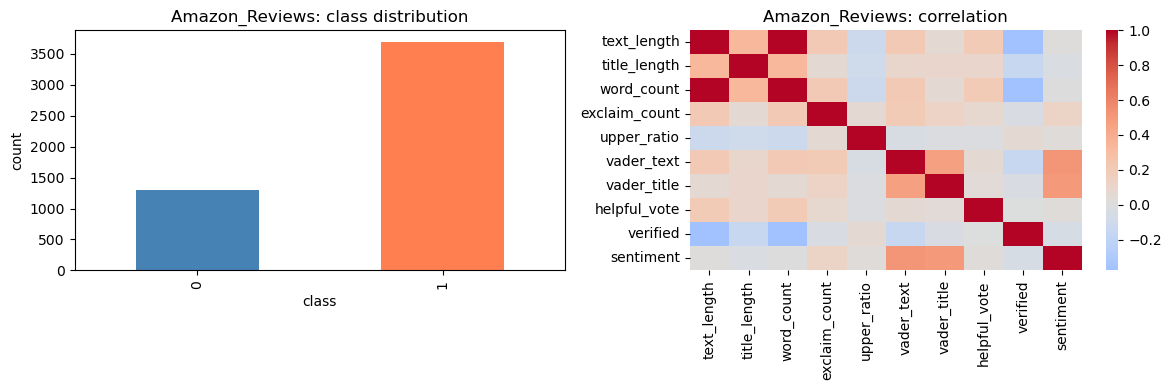

In [27]:
for k, (d, t) in DATA.items():
    viz.eda_plot(d, t, k)

## Step 4: One end-to-end graph run per dataset (with the fixed Reviewer)
This is the walkthrough: every node runs once, the Reviewer's decisions are printed, and SHAP shows what the final model uses. Train and test scores are shown side by side.

Heart_Disease: model=logreg bal_acc=0.847 mcc=0.704 auc=0.922 retries=1
planner: Heart_Disease: 242 train rows, risks: ['missing values']
ml: default/logreg thr=0.50 bal_acc=0.865 mcc=0.736
reviewer: 36 rows look mislabeled but dropping them did not clearly help (CV gain +0.064), reported only
reviewer: 12 impossible values -> retry_eda
eda: dropped 12 rows with impossible values
ml: default/logreg thr=0.50 bal_acc=0.847 mcc=0.704
reviewer: all checks passed
              train   test
f1            0.715  0.830
mcc           0.452  0.704
balanced_acc  0.726  0.847
recall        0.699  0.786
specificity   0.752  0.909
auc           0.817  0.922


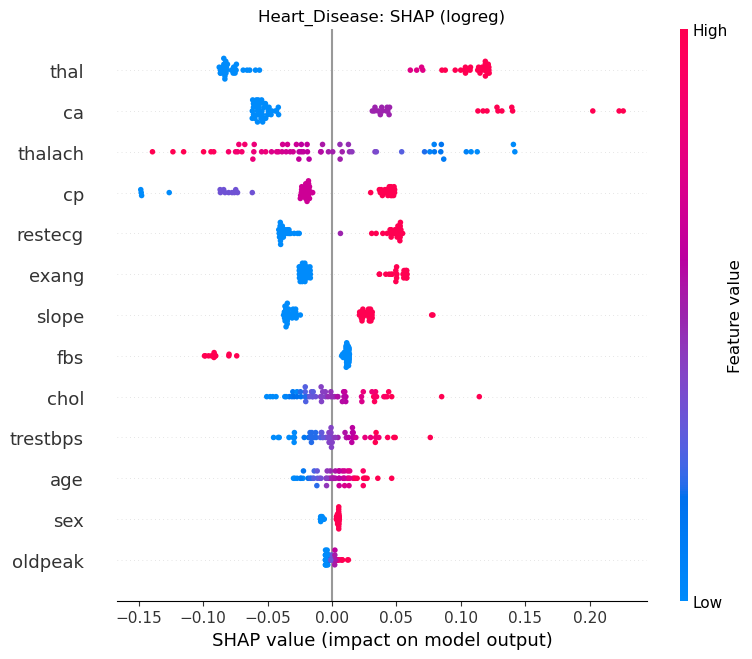

NYC_Taxi: model=logreg bal_acc=0.535 mcc=0.238 auc=0.595 retries=1
planner: NYC_Taxi: 4000 train rows, risks: ['imbalance (minority 29%)']
ml: default/logreg thr=0.50 bal_acc=0.535 mcc=0.238
reviewer: 71 rows look mislabeled but dropping them did not clearly help (CV gain +0.014), reported only
reviewer: 200 impossible values -> retry_eda
eda: dropped 200 rows with impossible values
ml: default/logreg thr=0.50 bal_acc=0.535 mcc=0.238
reviewer: retry changed nothing, stopping
              train   test
f1            0.832  0.896
mcc           0.143  0.238
balanced_acc  0.517  0.535
recall        0.998  1.000
specificity   0.036  0.070
auc           0.543  0.595


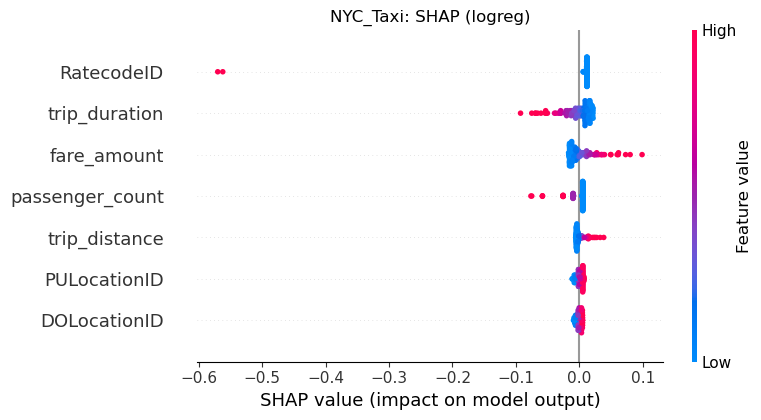

Amazon_Reviews: model=logreg bal_acc=0.762 mcc=0.559 auc=0.874 retries=1
planner: Amazon_Reviews: 4000 train rows, risks: ['imbalance (minority 33%)']
ml: default/rf thr=0.50 bal_acc=0.772 mcc=0.553
reviewer: 599 rows look mislabeled but dropping them did not clearly help (CV gain +0.012), reported only
reviewer: 200 impossible values -> retry_eda
eda: dropped 200 rows with impossible values
ml: default/logreg thr=0.50 bal_acc=0.762 mcc=0.559
reviewer: all checks passed
              train   test
f1            0.818  0.894
mcc           0.361  0.559
balanced_acc  0.656  0.762
recall        0.894  0.922
specificity   0.418  0.602
auc           0.739  0.874


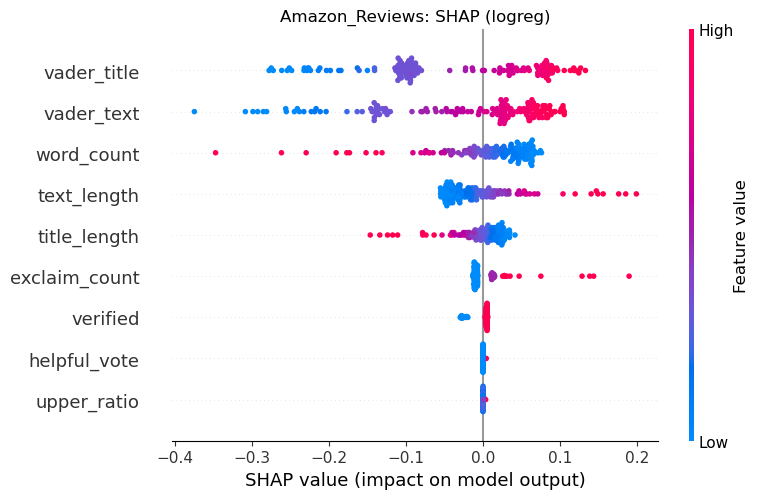

In [28]:
demo = {}
for k, (d, t) in DATA.items():
    d2 = ab.add_rid(d)
    train, test = ab.make_split(d2, t, seed=0)
    tr_c, info = ab.corrupt_train(train, t, k, label_noise=0.15, imp_rate=0.05, seed=0)
    app = ab.build_graph(use_reviewer=True, llm=llm, reviewer_mode="fixed")
    out = ab.run_graph(app, tr_c, test, t, k)
    demo[k] = out
    print("=" * 70); print(out["final_report"])
    tr_m, te_m = out["train_metrics"], out["metrics"]
    print(pd.DataFrame({"train": tr_m, "test": te_m}).loc[["f1", "mcc", "balanced_acc", "recall", "specificity", "auc"]].round(3))
    viz.shap_plot(out, k)

### Step 4b: The baselines on the same walkthrough run
Same seed-0 split, 15% wrong labels and 5% impossible values as Step 4. This shows what each baseline scores next to the graph with the fixed Reviewer. Run Step 4 first, because this uses its `demo` results. AutoGluon adds about a minute per dataset; set `RUN_AG_WALK = False` to skip it.

Heart_Disease | models chosen: {'always_positive': '-', 'single_agent': 'logreg', 'autogluon': 'WeightedEnsemble_L2'}


,always_positive,single_agent,autogluon,graph_reviewer_fixed
f1,0.629,0.852,0.800,0.830
mcc,0.000,0.736,0.636,0.704
balanced_acc,0.500,0.865,0.817,0.847
recall,1.000,0.821,0.786,0.786
specificity,0.000,0.909,0.848,0.909
auc,0.500,0.923,0.936,0.922


NYC_Taxi | models chosen: {'always_positive': '-', 'single_agent': 'logreg', 'autogluon': 'WeightedEnsemble_L2'}


,always_positive,single_agent,autogluon,graph_reviewer_fixed
f1,0.889,0.896,0.890,0.896
mcc,0.000,0.238,0.170,0.238
balanced_acc,0.500,0.535,0.537,0.535
recall,1.000,1.000,0.984,1.000
specificity,0.000,0.070,0.090,0.070
auc,0.500,0.561,0.581,0.595


Amazon_Reviews | models chosen: {'always_positive': '-', 'single_agent': 'rf', 'autogluon': 'WeightedEnsemble_L2'}


,always_positive,single_agent,autogluon,graph_reviewer_fixed
f1,0.85,0.886,0.903,0.894
mcc,0.00,0.553,0.605,0.559
balanced_acc,0.50,0.772,0.789,0.762
recall,1.00,0.893,0.923,0.922
specificity,0.00,0.651,0.655,0.602
auc,0.50,0.870,0.887,0.874


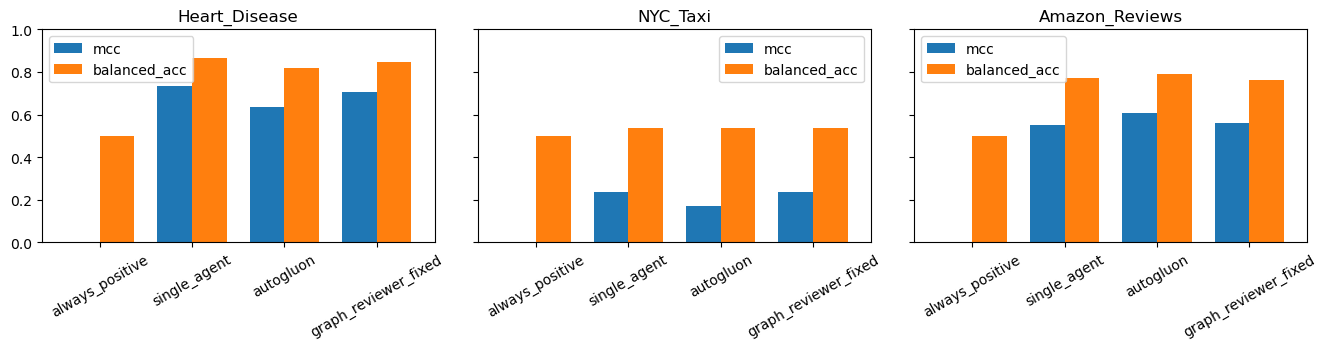

In [29]:
RUN_AG_WALK = True
walk = {}
for k, (d, t) in DATA.items():
    d2 = ab.add_rid(d)
    train, test = ab.make_split(d2, t, seed=0)
    tr_c, info = ab.corrupt_train(train, t, k, label_noise=0.15, imp_rate=0.05, seed=0)
    outs = {"always_positive": {"metrics": ab.always_positive(test[t]), "model": "-"},
            "single_agent": ab.run_single_agent(tr_c, test, t)}
    if RUN_AG_WALK:
        outs["autogluon"] = ab.run_autogluon(tr_c, test, t, f"walk_{k}", time_limit=60)
    tab = pd.DataFrame({n: r["metrics"] for n, r in outs.items()})
    tab["graph_reviewer_fixed"] = pd.Series(demo[k]["metrics"])
    print("=" * 70); print(k, "| models chosen:", {n: r.get("model") for n, r in outs.items()})
    show = tab.loc[["f1", "mcc", "balanced_acc", "recall", "specificity", "auc"]].round(3)
    display(show)
    walk[k] = show
fig, axes = plt.subplots(1, len(walk), figsize=(4.5 * len(walk), 3.6), sharey=True)
for ax, (k, show) in zip(np.atleast_1d(axes), walk.items()):
    show.loc[["mcc", "balanced_acc"]].T.plot.bar(ax=ax, rot=30, width=0.75)
    ax.set_title(k); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

## Step 5: Full benchmark on clean and corrupted data
Conditions are (label noise, impossible-value rate): (0, 0), (5%, 2%), (15%, 5%), (30%, 5%). Systems: always positive, single agent, graph without reviewer, graph with the old reviewer, graph with the fixed reviewer, and optionally AutoGluon.

In [30]:
ab.cv_gain_from_dropping.__defaults__ = ((0,),)

In [31]:
SEEDS = {"Heart_Disease": range(10), "Amazon_Reviews": range(3), "NYC_Taxi": range(3)}

In [32]:
import time
frames = [pd.read_csv("outputs/full_Heart_Disease.csv")]
for k in ["NYC_Taxi", "Amazon_Reviews"]:
    t0 = time.time()
    r = ab.run_experiment({k: DATA[k]}, seeds=SEEDS[k], use_autogluon=USE_AUTOGLUON, llm=llm,
                          out_csv=f"outputs/full_{k}.csv", verbose=True)
    frames.append(r)
    print(k, "done in", round((time.time() - t0) / 60, 1), "min")
res = pd.concat(frames, ignore_index=True)
res.to_csv("outputs/full_all.csv", index=False)
print(res.shape)

NYC_Taxi seed=0 label_noise=0.0 imp_rate=0.0
NYC_Taxi seed=0 label_noise=0.05 imp_rate=0.02
NYC_Taxi seed=0 label_noise=0.15 imp_rate=0.05
NYC_Taxi seed=0 label_noise=0.3 imp_rate=0.05
NYC_Taxi seed=1 label_noise=0.0 imp_rate=0.0
NYC_Taxi seed=1 label_noise=0.05 imp_rate=0.02
NYC_Taxi seed=1 label_noise=0.15 imp_rate=0.05
NYC_Taxi seed=1 label_noise=0.3 imp_rate=0.05
NYC_Taxi seed=2 label_noise=0.0 imp_rate=0.0
NYC_Taxi seed=2 label_noise=0.05 imp_rate=0.02
NYC_Taxi seed=2 label_noise=0.15 imp_rate=0.05
NYC_Taxi seed=2 label_noise=0.3 imp_rate=0.05
NYC_Taxi done in 24.9 min
Amazon_Reviews seed=0 label_noise=0.0 imp_rate=0.0
Amazon_Reviews seed=0 label_noise=0.05 imp_rate=0.02
Amazon_Reviews seed=0 label_noise=0.15 imp_rate=0.05
Amazon_Reviews seed=0 label_noise=0.3 imp_rate=0.05
Amazon_Reviews seed=1 label_noise=0.0 imp_rate=0.0
Amazon_Reviews seed=1 label_noise=0.05 imp_rate=0.02
Amazon_Reviews seed=1 label_noise=0.15 imp_rate=0.05
Amazon_Reviews seed=1 label_noise=0.3 imp_rate=0.05
A

## Step 6: Results tables (test set, mean ± standard deviation over seeds)

In [33]:
for k in DATA:
    print(f"\n===== {k} =====")
    display(viz.summary_table(res, k))


===== Heart_Disease =====


f1            mcc   balanced_acc         recall    specificity            auc
label_noise system                                                                                                        
0.00        always_positive         0.629 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.797 ± 0.049  0.646 ± 0.084  0.818 ± 0.041  0.757 ± 0.065  0.879 ± 0.057  0.896 ± 0.036
            graph_no_reviewer     0.797 ± 0.049  0.646 ± 0.084  0.818 ± 0.041  0.757 ± 0.065  0.879 ± 0.057  0.896 ± 0.036
            graph_reviewer_v1     0.793 ± 0.063  0.638 ± 0.106  0.814 ± 0.053  0.761 ± 0.086  0.867 ± 0.085   0.891 ± 0.04
            graph_reviewer_fixed  0.799 ± 0.043   0.65 ± 0.076   0.82 ± 0.037  0.761 ± 0.058  0.879 ± 0.057  0.896 ± 0.037
0.05        always_positive         0.629 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.801 ± 0.059  0.654 ± 0.102  0.822 ± 0.051  0.764 ± 0.085   0.879 ± 0.07   0.898 ± 0.04
            graph_no_reviewer     0.801 ± 0.059  0.654 ± 0.102  0.822 ± 0.051  0.764 ± 0.085   0.879 ± 0.07   0.898 ± 0.04
            graph_reviewer_v1      0.79 ± 0.041  0.632 ± 0.073  0.811 ± 0.035  0.761 ± 0.072  0.861 ± 0.073  0.891 ± 0.035
            graph_reviewer_fixed  0.799 ± 0.058    0.654 ± 0.1  0.821 ± 0.049  0.754 ± 0.072  0.888 ± 0.066    0.9 ± 0.042
0.15        always_positive         0.629 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.798 ± 0.058  0.651 ± 0.106  0.819 ± 0.052  0.757 ± 0.073  0.882 ± 0.078  0.878 ± 0.047
            graph_no_reviewer     0.798 ± 0.058  0.651 ± 0.106  0.819 ± 0.052  0.757 ± 0.073  0.882 ± 0.078  0.878 ± 0.047
            graph_reviewer_v1     0.756 ± 0.065  0.562 ± 0.133  0.777 ± 0.064  0.739 ± 0.072  0.815 ± 0.098  0.864 ± 0.046
            graph_reviewer_fixed  0.787 ± 0.057  0.628 ± 0.093  0.809 ± 0.047  0.757 ± 0.089  0.861 ± 0.072   0.87 ± 0.049
0.30        always_positive         0.629 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.723 ± 0.063  0.504 ± 0.102  0.749 ± 0.052  0.707 ± 0.086  0.791 ± 0.081  0.817 ± 0.071
            graph_no_reviewer     0.723 ± 0.063  0.504 ± 0.102  0.749 ± 0.052  0.707 ± 0.086  0.791 ± 0.081  0.817 ± 0.071
            graph_reviewer_v1     0.702 ± 0.089  0.443 ± 0.199  0.717 ± 0.097  0.711 ± 0.085  0.724 ± 0.168  0.805 ± 0.082
            graph_reviewer_fixed   0.71 ± 0.067  0.466 ± 0.128  0.731 ± 0.063  0.711 ± 0.076  0.752 ± 0.099  0.798 ± 0.081


===== NYC_Taxi =====


f1            mcc   balanced_acc         recall    specificity            auc
label_noise system                                                                                                        
0.00        always_positive         0.889 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.894 ± 0.002  0.202 ± 0.053  0.527 ± 0.013    1.0 ± 0.001  0.055 ± 0.026  0.586 ± 0.018
            graph_no_reviewer     0.894 ± 0.002  0.202 ± 0.053  0.527 ± 0.013    1.0 ± 0.001  0.055 ± 0.026  0.586 ± 0.018
            graph_reviewer_v1     0.841 ± 0.091  0.172 ± 0.047   0.546 ± 0.04  0.883 ± 0.201  0.208 ± 0.279  0.595 ± 0.017
            graph_reviewer_fixed  0.806 ± 0.019  0.129 ± 0.034   0.569 ± 0.02  0.785 ± 0.039  0.353 ± 0.063  0.596 ± 0.024
0.05        always_positive         0.889 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013      1.0 ± 0.0  0.055 ± 0.026  0.567 ± 0.007
            graph_no_reviewer     0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013      1.0 ± 0.0  0.055 ± 0.026  0.567 ± 0.007
            graph_reviewer_v1      0.86 ± 0.059  0.156 ± 0.076  0.532 ± 0.018  0.922 ± 0.136  0.142 ± 0.165  0.587 ± 0.012
            graph_reviewer_fixed   0.86 ± 0.059  0.156 ± 0.076  0.532 ± 0.018  0.922 ± 0.136  0.142 ± 0.165  0.587 ± 0.012
0.15        always_positive         0.889 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013      1.0 ± 0.0  0.055 ± 0.026  0.574 ± 0.013
            graph_no_reviewer     0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013      1.0 ± 0.0  0.055 ± 0.026  0.574 ± 0.013
            graph_reviewer_v1      0.84 ± 0.093  0.157 ± 0.074  0.534 ± 0.022  0.885 ± 0.198  0.183 ± 0.236   0.587 ± 0.01
            graph_reviewer_fixed   0.84 ± 0.093  0.157 ± 0.074  0.534 ± 0.022  0.885 ± 0.198  0.183 ± 0.236   0.587 ± 0.01
0.30        always_positive         0.889 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013      1.0 ± 0.0  0.055 ± 0.026  0.578 ± 0.023
            graph_no_reviewer     0.894 ± 0.003  0.206 ± 0.056  0.528 ± 0.013      1.0 ± 0.0  0.055 ± 0.026  0.578 ± 0.023
            graph_reviewer_v1      0.78 ± 0.106   0.13 ± 0.094  0.542 ± 0.007  0.764 ± 0.212   0.32 ± 0.226  0.571 ± 0.031
            graph_reviewer_fixed   0.78 ± 0.106   0.13 ± 0.094  0.542 ± 0.007  0.764 ± 0.212   0.32 ± 0.226  0.571 ± 0.031


===== Amazon_Reviews =====


f1            mcc   balanced_acc         recall    specificity            auc
label_noise system                                                                                                        
0.00        always_positive          0.85 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.898 ± 0.005  0.587 ± 0.021  0.782 ± 0.012  0.915 ± 0.006  0.649 ± 0.026  0.893 ± 0.007
            graph_no_reviewer     0.898 ± 0.005  0.587 ± 0.021  0.782 ± 0.012  0.915 ± 0.006  0.649 ± 0.026  0.893 ± 0.007
            graph_reviewer_v1     0.898 ± 0.005  0.587 ± 0.021  0.782 ± 0.012  0.915 ± 0.006  0.649 ± 0.026  0.893 ± 0.007
            graph_reviewer_fixed  0.898 ± 0.005  0.587 ± 0.021  0.782 ± 0.012  0.915 ± 0.006  0.649 ± 0.026  0.893 ± 0.007
0.05        always_positive          0.85 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.893 ± 0.004  0.574 ± 0.021   0.78 ± 0.014  0.904 ± 0.005  0.655 ± 0.029  0.887 ± 0.012
            graph_no_reviewer     0.893 ± 0.004  0.574 ± 0.021   0.78 ± 0.014  0.904 ± 0.005  0.655 ± 0.029  0.887 ± 0.012
            graph_reviewer_v1     0.895 ± 0.001  0.577 ± 0.005  0.778 ± 0.003  0.912 ± 0.003  0.644 ± 0.007  0.884 ± 0.005
            graph_reviewer_fixed  0.895 ± 0.001  0.577 ± 0.005  0.778 ± 0.003  0.912 ± 0.003  0.644 ± 0.007  0.884 ± 0.005
0.15        always_positive          0.85 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.882 ± 0.007  0.545 ± 0.018  0.771 ± 0.006  0.884 ± 0.014  0.659 ± 0.007  0.862 ± 0.013
            graph_no_reviewer     0.882 ± 0.007  0.545 ± 0.018  0.771 ± 0.006  0.884 ± 0.014  0.659 ± 0.007  0.862 ± 0.013
            graph_reviewer_v1     0.886 ± 0.014  0.553 ± 0.035   0.77 ± 0.015   0.895 ± 0.03  0.645 ± 0.038  0.861 ± 0.013
            graph_reviewer_fixed  0.886 ± 0.014  0.553 ± 0.035   0.77 ± 0.015   0.895 ± 0.03  0.645 ± 0.038  0.861 ± 0.013
0.30        always_positive          0.85 ± 0.0      0.0 ± 0.0      0.5 ± 0.0      1.0 ± 0.0      0.0 ± 0.0      0.5 ± 0.0
            single_agent          0.889 ± 0.004  0.532 ± 0.024  0.744 ± 0.017   0.923 ± 0.01  0.564 ± 0.041  0.863 ± 0.009
            graph_no_reviewer     0.889 ± 0.004  0.532 ± 0.024  0.744 ± 0.017   0.923 ± 0.01  0.564 ± 0.041  0.863 ± 0.009
            graph_reviewer_v1     0.889 ± 0.003  0.532 ± 0.026  0.743 ± 0.028  0.923 ± 0.022  0.563 ± 0.077  0.865 ± 0.006
            graph_reviewer_fixed  0.889 ± 0.003  0.532 ± 0.026  0.743 ± 0.028  0.923 ± 0.022  0.563 ± 0.077  0.865 ± 0.006

## Step 7: Charts

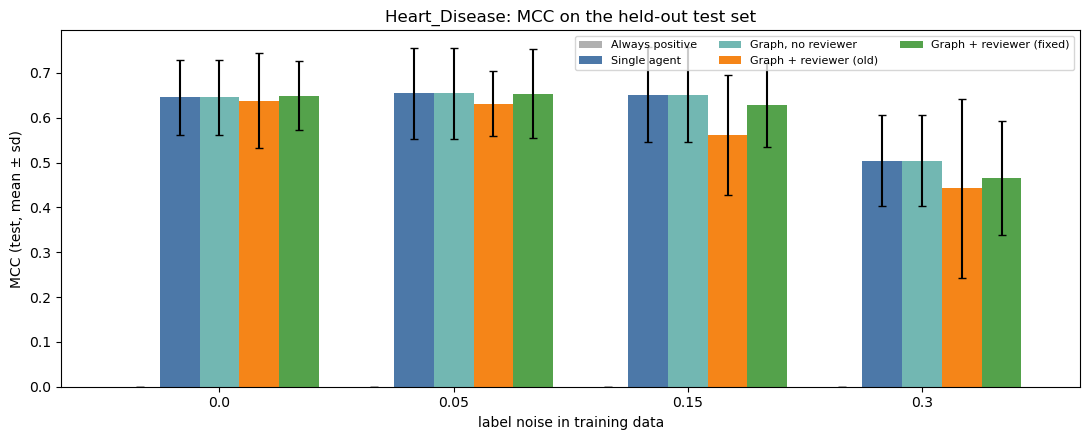

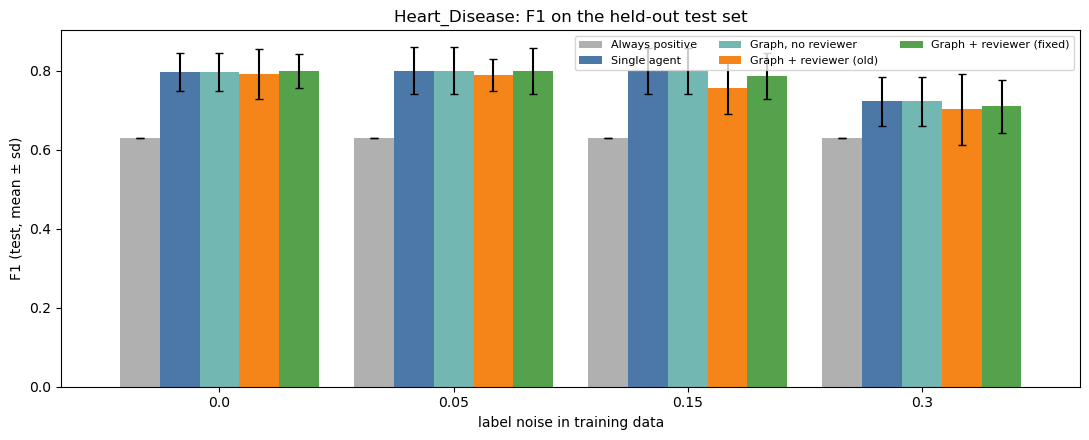

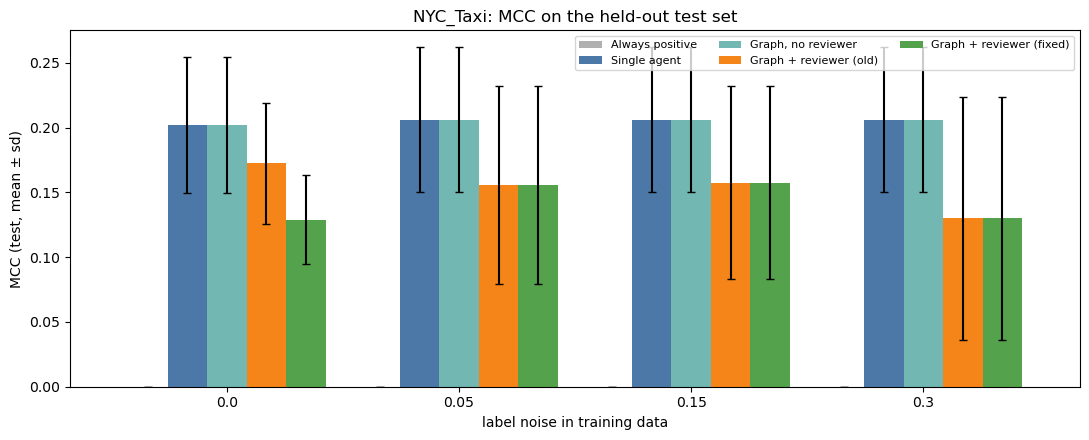

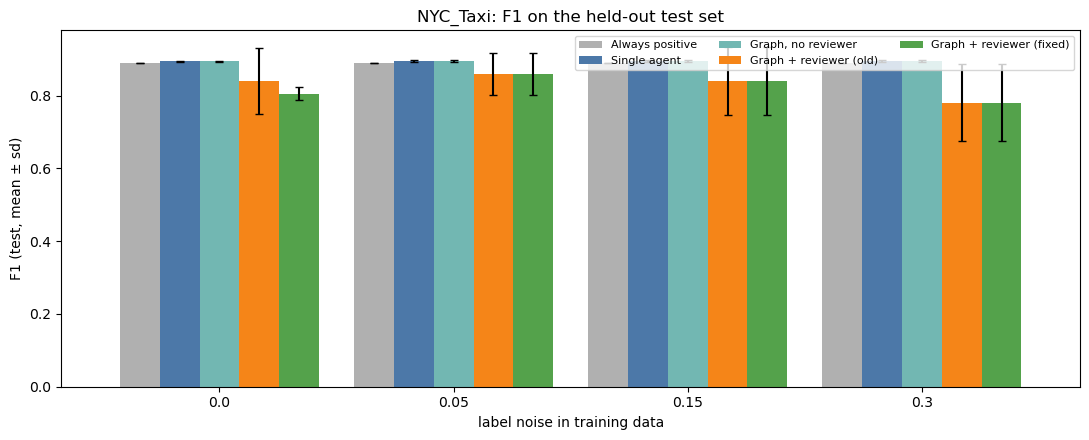

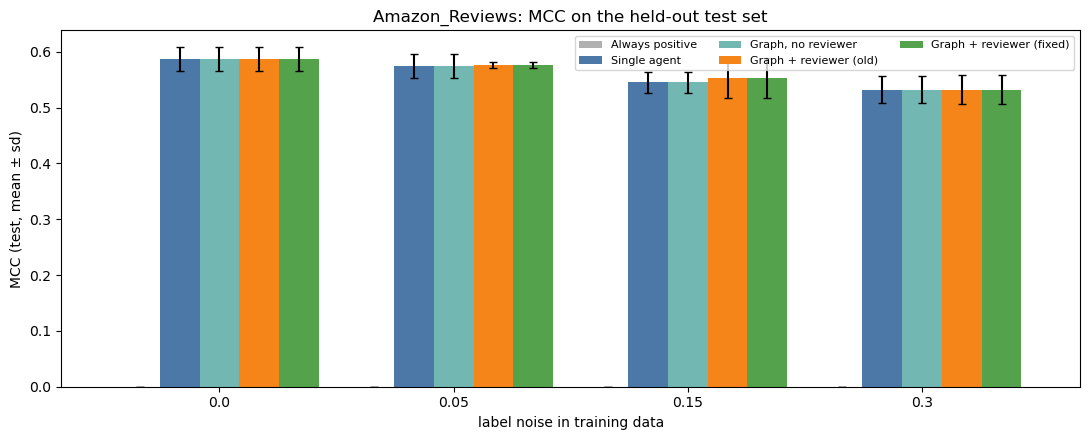

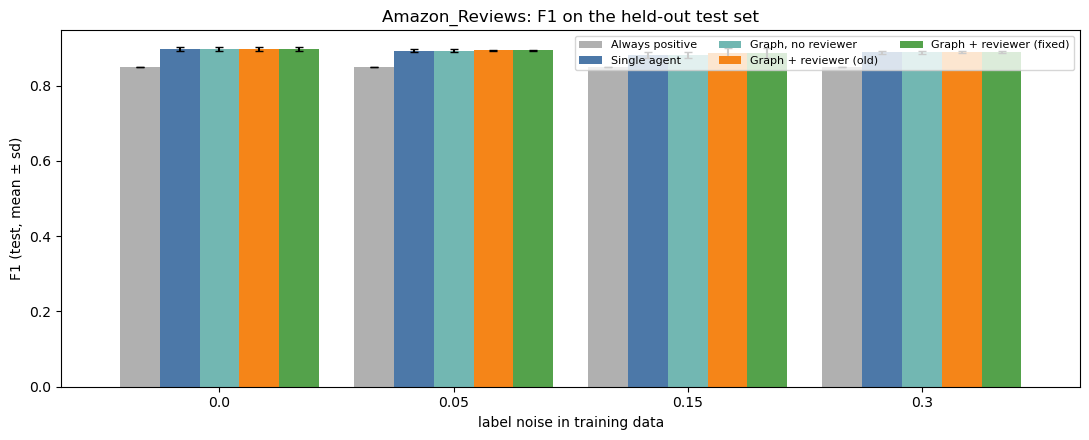

In [34]:
for k in DATA:
    viz.bar_by_condition(res, k, "mcc")
    viz.bar_by_condition(res, k, "f1", title=f"{k}: F1 on the held-out test set")

### F1 versus MCC: why F1 alone can mislead

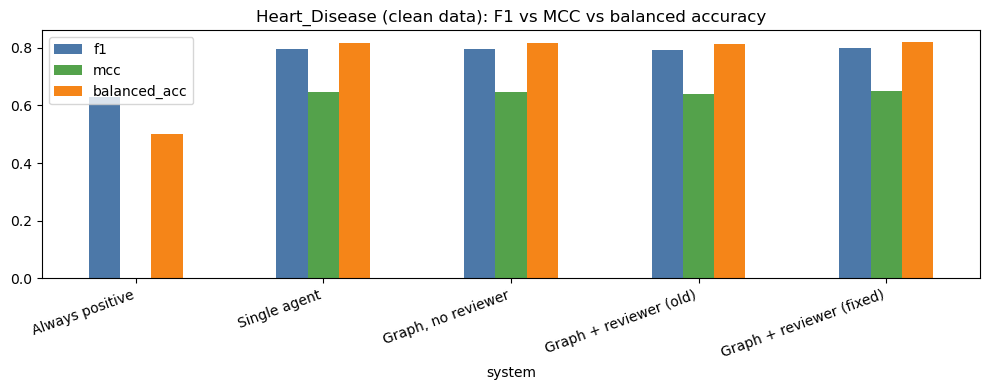

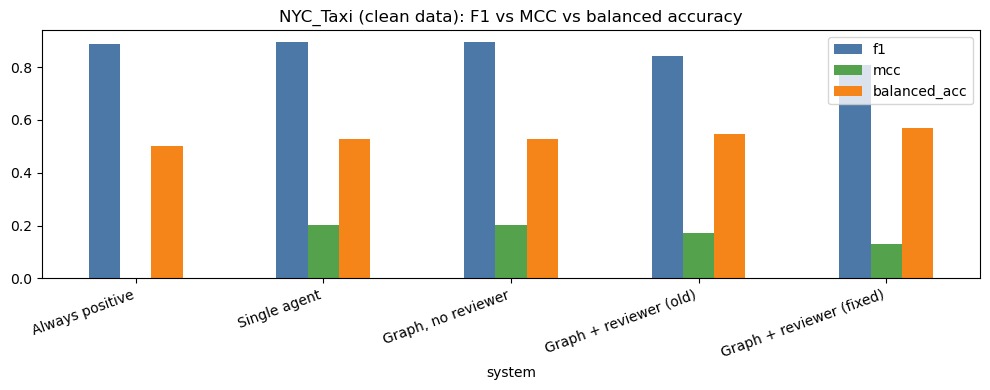

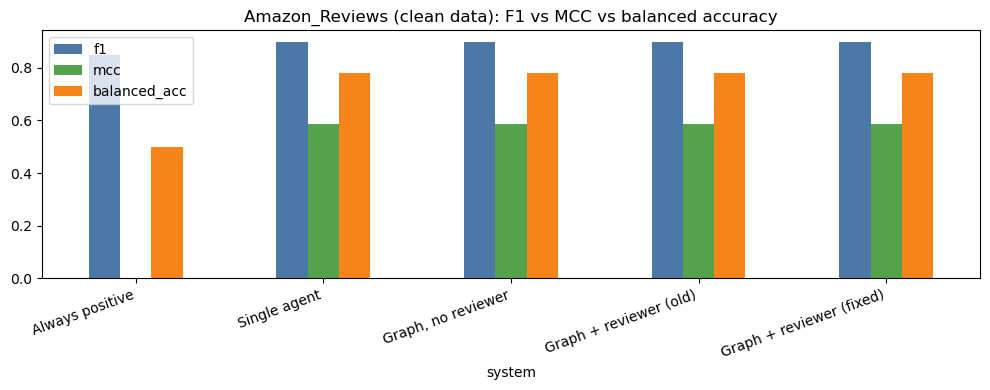

In [35]:
for k in DATA:
    viz.f1_vs_mcc(res, k)

### Train versus test (overfitting check)

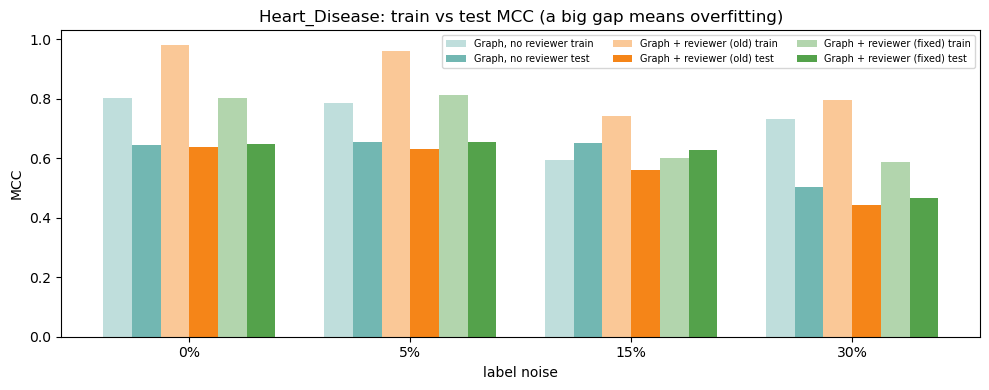

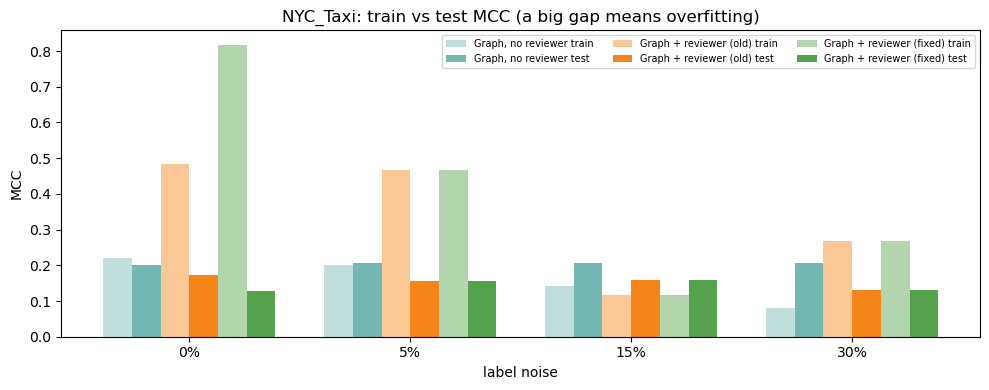

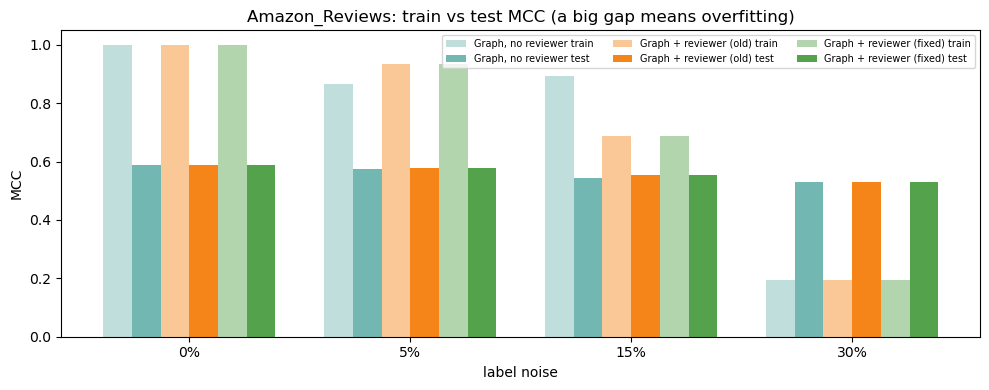

In [36]:
for k in DATA:
    viz.train_vs_test(res, k, "mcc")

### Did the Reviewer find the corrupted rows?

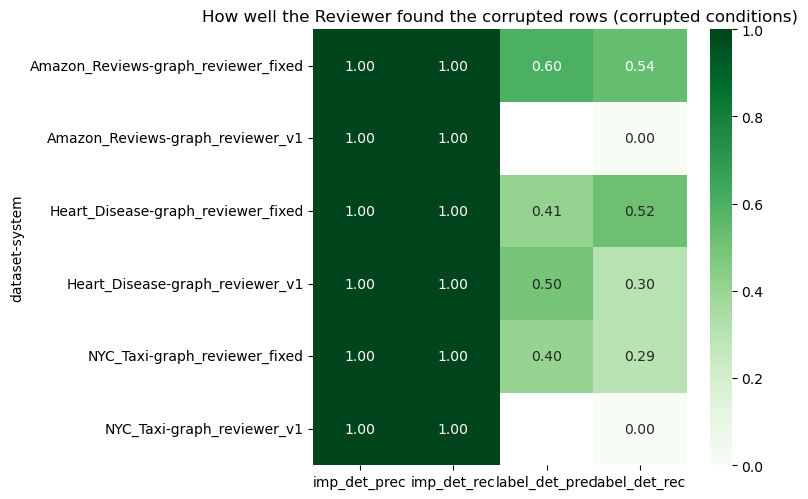

Rows the fixed Reviewer flagged but did not remove (mean per run):
                            n_flagged_label  n_dropped_label
dataset        label_noise                                  
Amazon_Reviews 0.00                   269.3              0.0
               0.05                   362.7              0.0
               0.15                   539.3              0.0
               0.30                   607.7              0.0
Heart_Disease  0.00                    28.5              0.0
               0.05                    34.9              0.0
               0.15                    45.5              0.0
               0.30                    48.6              0.0
NYC_Taxi       0.00                   616.0              0.0
               0.05                   432.3              0.0
               0.15                   388.7              0.0
               0.30                   373.0              0.0


In [37]:
viz.detection_heatmap(res)
print("Rows the fixed Reviewer flagged but did not remove (mean per run):")
print(res[res.system == "graph_reviewer_fixed"].groupby(["dataset", "label_noise"])[["n_flagged_label", "n_dropped_label"]].mean().round(1))

## Step 8: Leakage test
A near-copy of the label is added as a feature. A system that does not catch it scores close to 1.0 without any real skill. The honest score is about 0.65 on Heart Disease.

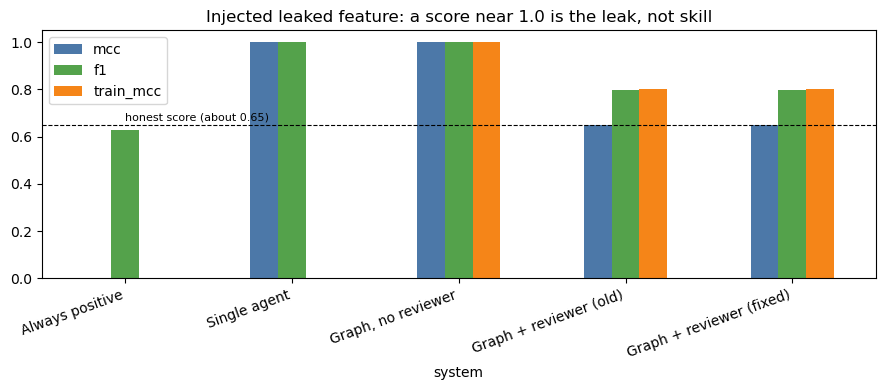

                       mcc     f1 leaky_flagged
system                                         
always_positive       0.00  0.629           NaN
graph_no_reviewer     1.00  1.000           0.0
graph_reviewer_fixed  0.65  0.799           1.0
graph_reviewer_v1     0.65  0.799           1.0
single_agent          1.00  1.000           NaN


In [38]:
leak = ab.run_experiment({"Heart_Disease": DATA["Heart_Disease"]}, seeds=SEEDS["Heart_Disease"], conditions=[(0.0, 0.0)],
                         leak=True, llm=llm, out_csv="outputs/full_leak.csv", verbose=False)
viz.leak_plot(leak)
print(leak.groupby("system")[["mcc", "f1", "leaky_flagged"]].mean().round(3))

## Step 9: Findings (computed from the results above)

In [39]:
m = res.groupby(["dataset", "label_noise", "system"])["mcc"].mean().unstack("system")
f = res.groupby(["dataset", "label_noise", "system"])["f1"].mean().unstack("system")
print("MCC, mean over seeds"); display(m.round(3))
print("F1, mean over seeds");  display(f.round(3))
d = (m["graph_reviewer_fixed"] - m["graph_no_reviewer"]).round(3)
print("\nFixed Reviewer minus no Reviewer (MCC):"); print(d.to_string())
print("\nLeak test, fixed reviewer flagged the leaky feature in", int(leak[leak.system == "graph_reviewer_fixed"].leaky_flagged.sum()),
      "of", int((leak.system == "graph_reviewer_fixed").sum()), "runs")

MCC, mean over seeds


system                      always_positive  graph_no_reviewer  graph_reviewer_fixed  graph_reviewer_v1  single_agent
dataset        label_noise                                                                                           
Amazon_Reviews 0.00                     0.0              0.587                 0.587              0.587         0.587
               0.05                     0.0              0.574                 0.577              0.577         0.574
               0.15                     0.0              0.545                 0.553              0.553         0.545
               0.30                     0.0              0.532                 0.532              0.532         0.532
Heart_Disease  0.00                     0.0              0.646                 0.650              0.638         0.646
               0.05                     0.0              0.654                 0.654              0.632         0.654
               0.15                     0.0              0.651                 0.628              0.562         0.651
               0.30                     0.0              0.504                 0.466              0.443         0.504
NYC_Taxi       0.00                     0.0              0.202                 0.129              0.172         0.202
               0.05                     0.0              0.206                 0.156              0.156         0.206
               0.15                     0.0              0.206                 0.157              0.157         0.206
               0.30                     0.0              0.206                 0.130              0.130         0.206

F1, mean over seeds


system                      always_positive  graph_no_reviewer  graph_reviewer_fixed  graph_reviewer_v1  single_agent
dataset        label_noise                                                                                           
Amazon_Reviews 0.00                   0.850              0.898                 0.898              0.898         0.898
               0.05                   0.850              0.893                 0.895              0.895         0.893
               0.15                   0.850              0.882                 0.886              0.886         0.882
               0.30                   0.850              0.889                 0.889              0.889         0.889
Heart_Disease  0.00                   0.629              0.797                 0.799              0.793         0.797
               0.05                   0.629              0.801                 0.799              0.790         0.801
               0.15                   0.629              0.798                 0.787              0.756         0.798
               0.30                   0.629              0.723                 0.710              0.702         0.723
NYC_Taxi       0.00                   0.889              0.894                 0.806              0.841         0.894
               0.05                   0.889              0.894                 0.860              0.860         0.894
               0.15                   0.889              0.894                 0.840              0.840         0.894
               0.30                   0.889              0.894                 0.780              0.780         0.894


Fixed Reviewer minus no Reviewer (MCC):
dataset         label_noise
Amazon_Reviews  0.00           0.000
                0.05           0.003
                0.15           0.008
                0.30          -0.000
Heart_Disease   0.00           0.003
                0.05          -0.001
                0.15          -0.023
                0.30          -0.038
NYC_Taxi        0.00          -0.073
                0.05          -0.050
                0.15          -0.049
                0.30          -0.076

Leak test, fixed reviewer flagged the leaky feature in 10 of 10 runs


### How to read the findings
- Compare MCC and balanced accuracy first. F1 is shown for continuity with the first version, but the always-positive row shows how high F1 can be without any skill.
- A Reviewer that matches the no-reviewer score on clean data and catches impossible values and leaks is doing its job. Do not claim it improves accuracy unless the table shows a gap larger than the standard deviation.
- Write the final conclusions from the numbers printed in this notebook, not from the earlier README.

## Step 10: AutoGluon on the same splits
AutoGluon gets the same seeds, the same corrupted training data and the same clean test set as every other system. It runs here, as a separate pass, so that the long benchmark above does not have to be repeated. Results are saved to `outputs/full_autogluon_<dataset>.csv`, one file per dataset, and combined into `outputs/full_autogluon.csv`.

In [40]:
import os, time, pandas as pd
from pathlib import Path
import agentic_bench as ab

pd.set_option("display.width", 140)
AG_SEEDS = {"Heart_Disease": range(10), "Amazon_Reviews": range(3), "NYC_Taxi": range(3)}
AG_TIME = 60   # seconds per fit; lower to 30 if it is too slow
Path("outputs").mkdir(exist_ok=True)
RERUN_AG = False   # False: reuse saved outputs/full_autogluon_<dataset>.csv, True: run again (about 1 hour)

for k in ["Heart_Disease", "Amazon_Reviews", "NYC_Taxi"]:   # one dataset at a time, saved as it goes
    if os.path.exists(f"outputs/full_autogluon_{k}.csv") and not RERUN_AG:
        print("reusing saved AutoGluon results for", k); continue
    df, target = DATA[k]
    df = ab.add_rid(df)
    rows = []
    for seed in AG_SEEDS[k]:
        train, test = ab.make_split(df, target, seed)
        for ln, ir in ab.DEFAULT_CONDITIONS:
            tr_c, _ = ab.corrupt_train(train, target, k, ln, ir, seed)
            t0 = time.time()
            ag_res = ab.run_autogluon(tr_c, test, target, f"{k}_{seed}", time_limit=AG_TIME)
            rows.append({"dataset": k, "system": "autogluon", "seed": seed, "label_noise": ln,
                         "imp_rate": ir, **ag_res["metrics"], "model": ag_res["model"],
                         "seconds": round(time.time() - t0, 1)})
            pd.DataFrame(rows).to_csv(f"outputs/full_autogluon_{k}.csv", index=False)
            print(k, seed, ln, round(ag_res["metrics"]["mcc"], 3))

reusing saved AutoGluon results for Heart_Disease
reusing saved AutoGluon results for Amazon_Reviews
reusing saved AutoGluon results for NYC_Taxi


In [41]:
ag = pd.concat([pd.read_csv(f"outputs/full_autogluon_{k}.csv") for k in AG_SEEDS])
ag.to_csv("outputs/full_autogluon.csv", index=False)
base = pd.read_csv("outputs/full_all.csv")
allr = pd.concat([base, ag], ignore_index=True)
tab = (allr[allr.system.isin(["single_agent", "graph_reviewer_fixed", "autogluon"])]
       .groupby(["dataset", "label_noise", "system"])[["mcc", "f1"]].mean().round(3).unstack("system"))
print(tab["mcc"])

system                      autogluon  graph_reviewer_fixed  single_agent
dataset        label_noise                                               
Amazon_Reviews 0.00             0.585                 0.587         0.587
               0.05             0.589                 0.577         0.574
               0.15             0.581                 0.553         0.545
               0.30             0.507                 0.532         0.532
Heart_Disease  0.00             0.642                 0.650         0.646
               0.05             0.623                 0.654         0.654
               0.15             0.605                 0.628         0.651
               0.30             0.468                 0.466         0.504
NYC_Taxi       0.00             0.094                 0.129         0.202
               0.05             0.093                 0.156         0.206
               0.15             0.118                 0.157         0.206
               0.30             0.046 

## Step 11: Follow-up studies
These close the gaps listed at the end of the blog draft. The slow ones are switched off by default. Turn a flag on, run its cell, and the results are saved to `outputs/` so a later run just reloads them.

In [57]:
RUN_AG_LEAK = True          # about 10 minutes
RUN_NATURAL_LEAK = True     # about 15-20 minutes
RUN_AG_LONG = True         # AutoGluon with 300 s per fit, about 1 hour
RUN_MORE_SEEDS = False      # 5 extra seeds on taxi and Amazon, 1-2 hours per dataset
RUN_LLM_STRATEGY = True    # needs `ollama serve` and llama3.2, about 30-40 minutes

def load_all():
    """Main results plus the same-split AutoGluon run, with no duplicated AutoGluon rows."""
    main = pd.read_csv("outputs/full_all.csv")
    main = main[main.system != "autogluon"]
    return pd.concat([main, pd.read_csv("outputs/full_autogluon.csv")], ignore_index=True)

allr = load_all()
print(allr.groupby("dataset").seed.nunique())

dataset
Amazon_Reviews     3
Heart_Disease     10
NYC_Taxi           3
Name: seed, dtype: int64


### 11a. Spread and paired differences (closes: spread numbers for the comparison table)
Every system sees the same split for a given seed, so differences are computed per seed. A mean difference smaller than about two standard errors is a tie.

In [43]:
SYS3 = ["single_agent", "graph_reviewer_fixed", "autogluon"]

def spread(df):
    b = df[df.system.isin(SYS3)]
    print("MCC mean, std and number of seeds")
    display(b.groupby(["dataset", "label_noise", "system"])["mcc"].agg(["mean", "std", "count"]).round(3).unstack("system"))
    p = b.pivot_table(index=["dataset", "label_noise", "seed"], columns="system", values="mcc").reset_index()
    for a_, b_ in [("autogluon", "single_agent"), ("graph_reviewer_fixed", "single_agent")]:
        p["diff"] = p[a_] - p[b_]
        g = p.groupby(["dataset", "label_noise"])["diff"].agg(["mean", "std", "count"])
        g["se"] = g["std"] / np.sqrt(g["count"])
        g["tie"] = g["mean"].abs() <= 2 * g["se"]
        print(f"\n{a_} minus {b_} (MCC per seed)")
        display(g.round(3))

spread(allr)

MCC mean, std and number of seeds


mean                                         std                                       count  \
system                     autogluon graph_reviewer_fixed single_agent autogluon graph_reviewer_fixed single_agent autogluon   
dataset        label_noise                                                                                                     
Amazon_Reviews 0.00            0.585                0.587        0.587     0.029                0.021        0.021         3   
               0.05            0.589                0.577        0.574     0.023                0.005        0.021         3   
               0.15            0.581                0.553        0.545     0.034                0.035        0.018         3   
               0.30            0.507                0.532        0.532     0.080                0.026        0.024         3   
Heart_Disease  0.00            0.642                0.650        0.646     0.093                0.076        0.084        10   
               0.05            0.623                0.654        0.654     0.096                0.100        0.102        10   
               0.15            0.605                0.628        0.651     0.098                0.093        0.106        10   
               0.30            0.468                0.466        0.504     0.140                0.128        0.102        10   
NYC_Taxi       0.00            0.094                0.129        0.202     0.030                0.034        0.053         3   
               0.05            0.093                0.156        0.206     0.031                0.076        0.056         3   
               0.15            0.118                0.157        0.206     0.045                0.074        0.056         3   
               0.30            0.046                0.130        0.206     0.060                0.094        0.056         3   

                                                              
system                     graph_reviewer_fixed single_agent  
dataset        label_noise                                    
Amazon_Reviews 0.00                           3            3  
               0.05                           3            3  
               0.15                           3            3  
               0.30                           3            3  
Heart_Disease  0.00                          10           10  
               0.05                          10           10  
               0.15                          10           10  
               0.30                          10           10  
NYC_Taxi       0.00                           3            3  
               0.05                           3            3  
               0.15                           3            3  
               0.30                           3            3


autogluon minus single_agent (MCC per seed)


mean    std  count     se    tie
dataset        label_noise                                   
Amazon_Reviews 0.00        -0.001  0.024      3  0.014   True
               0.05         0.015  0.009      3  0.005  False
               0.15         0.036  0.017      3  0.010  False
               0.30        -0.025  0.056      3  0.032   True
Heart_Disease  0.00        -0.004  0.058     10  0.018   True
               0.05        -0.031  0.119     10  0.038   True
               0.15        -0.046  0.083     10  0.026   True
               0.30        -0.036  0.131     10  0.041   True
NYC_Taxi       0.00        -0.108  0.024      3  0.014  False
               0.05        -0.113  0.043      3  0.025  False
               0.15        -0.088  0.057      3  0.033  False
               0.30        -0.160  0.033      3  0.019  False


graph_reviewer_fixed minus single_agent (MCC per seed)


mean    std  count     se    tie
dataset        label_noise                                   
Amazon_Reviews 0.00         0.000  0.000      3  0.000   True
               0.05         0.003  0.016      3  0.009   True
               0.15         0.008  0.018      3  0.010   True
               0.30        -0.000  0.010      3  0.006   True
Heart_Disease  0.00         0.003  0.010     10  0.003   True
               0.05        -0.001  0.041     10  0.013   True
               0.15        -0.023  0.077     10  0.024   True
               0.30        -0.038  0.065     10  0.021   True
NYC_Taxi       0.00        -0.073  0.022      3  0.013  False
               0.05        -0.050  0.087      3  0.050   True
               0.15        -0.049  0.084      3  0.049   True
               0.30        -0.076  0.079      3  0.046   True

### 11b. Check the taxi balanced accuracy numbers (closes: the 0.569 against 0.527 claim)

In [44]:
t = allr[(allr.dataset == "NYC_Taxi") & (allr.label_noise == 0.0)]
display(t.groupby("system")[["balanced_acc", "mcc", "f1", "recall", "specificity"]].mean().round(3))

,balanced_acc,mcc,f1,recall,specificity
system,,,,,
always_positive,0.500,0.000,0.889,1.000,0.000
autogluon,0.527,0.094,0.877,0.958,0.095
graph_no_reviewer,0.527,0.202,0.894,1.000,0.055
graph_reviewer_fixed,0.569,0.129,0.806,0.785,0.353
graph_reviewer_v1,0.546,0.172,0.841,0.883,0.208
single_agent,0.527,0.202,0.894,1.000,0.055


### 11c. AutoGluon through the leak test (closes: AutoGluon in the leak test)
The same Heart Disease leak test as Step 8, 10 seeds, with AutoGluon added.

In [45]:
import os
path = "outputs/full_ag_leak.csv"
if os.path.exists(path):
    ag_leak = pd.read_csv(path); print("loaded", path)
elif RUN_AG_LEAK:
    df, target = DATA["Heart_Disease"]
    df = ab.add_rid(ab.add_leaky_feature(df, target))
    rows = []
    for seed in range(10):
        train, test = ab.make_split(df, target, seed)
        tr_c, _ = ab.corrupt_train(train, target, "Heart_Disease", 0.0, 0.0, seed)
        r = ab.run_autogluon(tr_c, test, target, f"leak_{seed}", time_limit=60)
        rows.append({"system": "autogluon", "seed": seed, **r["metrics"]})
        print(seed, round(r["metrics"]["mcc"], 3))
    ag_leak = pd.DataFrame(rows); ag_leak.to_csv(path, index=False)
else:
    ag_leak = None; print("skipped (RUN_AG_LEAK is False)")
if ag_leak is not None:
    both = pd.concat([leak[["system", "seed", "mcc", "f1"]], ag_leak[["system", "seed", "mcc", "f1"]]])
    display(both.groupby("system")[["mcc", "f1"]].mean().round(3))

0 1.0
1 1.0
2 1.0
3 1.0
4 1.0
5 1.0
6 1.0
7 1.0
8 1.0
9 1.0


,mcc,f1
system,,
always_positive,0.00,0.629
autogluon,1.00,1.000
graph_no_reviewer,1.00,1.000
graph_reviewer_fixed,0.65,0.799
graph_reviewer_v1,0.65,0.799
single_agent,1.00,1.000


### 11d. The natural leak, `payment_type` (closes: re-test the natural leak with the fixed Reviewer)
Cash tips are not recorded, so the payment type almost gives away the tip. Here it is kept as a feature. If `payment_type` shows up in `features_dropped` for the fixed Reviewer, the score-jump check now catches a leak that was not planted.

In [46]:
path = "outputs/full_natural_leak.csv"
if os.path.exists(path):
    nat = pd.read_csv(path); print("loaded", path)
elif RUN_NATURAL_LEAK:
    df_nat, t_nat = ab.load_nyc(NYC_PARQUET, n=5000, keep_payment_type=True)
    nat = ab.run_experiment({"NYC_Taxi": (df_nat, t_nat)}, seeds=range(3), conditions=[(0.0, 0.0)],
                            use_autogluon=True, out_csv=path, verbose=False)
else:
    nat = None; print("skipped (RUN_NATURAL_LEAK is False)")
if nat is not None:
    display(nat.groupby("system")[["mcc", "f1", "balanced_acc"]].mean().round(3))
    cols = [c for c in ["system", "seed", "mcc", "features_dropped", "leaky_flagged"] if c in nat.columns]
    display(nat[nat.system.isin(["graph_reviewer_v1", "graph_reviewer_fixed"])][cols])

,mcc,f1,balanced_acc
system,,,
always_positive,0.000,0.889,0.500
autogluon,0.912,0.983,0.934
graph_no_reviewer,0.915,0.983,0.934
graph_reviewer_fixed,0.094,0.717,0.553
graph_reviewer_v1,0.915,0.983,0.934
single_agent,0.915,0.983,0.934


,system,seed,mcc,features_dropped,leaky_flagged
3,graph_reviewer_v1,0,0.911346,,False
4,graph_reviewer_fixed,0,0.085068,payment_type,False
9,graph_reviewer_v1,1,0.914553,,False
10,graph_reviewer_fixed,1,0.062276,payment_type,False
15,graph_reviewer_v1,2,0.917756,,False
16,graph_reviewer_fixed,2,0.134256,payment_type,False


### 11e. AutoGluon with a longer time limit (closes: only 60 seconds per fit)
Heart Disease and NYC Taxi, 3 seeds, clean and 30% wrong labels, 300 seconds per fit.

In [55]:
path = "outputs/full_ag_300s.csv"
if os.path.exists(path):
    long_ = pd.read_csv(path); print("loaded", path)
elif RUN_AG_LONG:
    rows = []
    for k in ["Heart_Disease", "NYC_Taxi"]:
        df, target = DATA[k]; df = ab.add_rid(df)
        for seed in range(3):
            train, test = ab.make_split(df, target, seed)
            for ln, ir in [(0.0, 0.0), (0.30, 0.05)]:
                tr_c, _ = ab.corrupt_train(train, target, k, ln, ir, seed)
                r = ab.run_autogluon(tr_c, test, target, f"long_{k}_{seed}", time_limit=300)
                rows.append({"dataset": k, "seed": seed, "label_noise": ln, "system": "autogluon_300s", **r["metrics"]})
                pd.DataFrame(rows).to_csv(path, index=False)
                print(k, seed, ln, round(r["metrics"]["mcc"], 3))
    long_ = pd.DataFrame(rows)
else:
    long_ = None; print("skipped (RUN_AG_LONG is False)")
if long_ is not None:
    short = allr[(allr.system == "autogluon") & (allr.seed < 3) & (allr.label_noise.isin([0.0, 0.30]))
                 & (allr.dataset.isin(["Heart_Disease", "NYC_Taxi"]))]
    display(pd.concat([short, long_]).groupby(["dataset", "label_noise", "system"])["mcc"].mean().round(3).unstack("system"))

Heart_Disease 0 0.0 0.74
Heart_Disease 0 0.3 0.436
Heart_Disease 1 0.0 0.538
Heart_Disease 1 0.3 0.273
Heart_Disease 2 0.0 0.67
Heart_Disease 2 0.3 0.538
NYC_Taxi 0 0.0 0.109
NYC_Taxi 0 0.3 0.108
NYC_Taxi 1 0.0 0.06
NYC_Taxi 1 0.3 -0.012
NYC_Taxi 2 0.0 0.113
NYC_Taxi 2 0.3 0.042


system                     autogluon  autogluon_300s
dataset       label_noise                           
Heart_Disease 0.0              0.649           0.649
              0.3              0.416           0.416
NYC_Taxi      0.0              0.094           0.094
              0.3              0.046           0.046

### 11f. More seeds on taxi and Amazon (closes: only 3 seeds)
Adds seeds 3 to 7 for the two datasets that had 3. Each dataset is saved on its own, so you can stop and come back.

In [58]:
for k in ["Amazon_Reviews", "NYC_Taxi"]:
    path = f"outputs/more_{k}.csv"
    if os.path.exists(path):
        print("found", path); continue
    if not RUN_MORE_SEEDS:
        print("skipped", k, "(RUN_MORE_SEEDS is False)"); continue
    t0 = time.time()
    ab.run_experiment({k: DATA[k]}, seeds=range(3, 8), use_autogluon=True, out_csv=path, verbose=False)
    print(k, "done in", round((time.time() - t0) / 60, 1), "min")

parts = [allr] + [pd.read_csv(f"outputs/more_{k}.csv") for k in ["Amazon_Reviews", "NYC_Taxi"]
                  if os.path.exists(f"outputs/more_{k}.csv")]
allr_more = pd.concat(parts, ignore_index=True).drop_duplicates(["dataset", "system", "seed", "label_noise"])
print(allr_more.groupby("dataset").seed.nunique())
if len(parts) > 1:
    spread(allr_more)

found outputs/more_Amazon_Reviews.csv
skipped NYC_Taxi (RUN_MORE_SEEDS is False)
dataset
Amazon_Reviews     6
Heart_Disease     10
NYC_Taxi           3
Name: seed, dtype: int64
MCC mean, std and number of seeds


mean                                         std                                       count  \
system                     autogluon graph_reviewer_fixed single_agent autogluon graph_reviewer_fixed single_agent autogluon   
dataset        label_noise                                                                                                     
Amazon_Reviews 0.00            0.590                0.591        0.591     0.020                0.021        0.021         6   
               0.05            0.593                0.578        0.581     0.033                0.018        0.020         6   
               0.15            0.573                0.550        0.549     0.027                0.026        0.015         5   
               0.30            0.517                0.517        0.519     0.059                0.028        0.024         5   
Heart_Disease  0.00            0.642                0.650        0.646     0.093                0.076        0.084        10   
               0.05            0.623                0.654        0.654     0.096                0.100        0.102        10   
               0.15            0.605                0.628        0.651     0.098                0.093        0.106        10   
               0.30            0.468                0.466        0.504     0.140                0.128        0.102        10   
NYC_Taxi       0.00            0.094                0.129        0.202     0.030                0.034        0.053         3   
               0.05            0.093                0.156        0.206     0.031                0.076        0.056         3   
               0.15            0.118                0.157        0.206     0.045                0.074        0.056         3   
               0.30            0.046                0.130        0.206     0.060                0.094        0.056         3   

                                                              
system                     graph_reviewer_fixed single_agent  
dataset        label_noise                                    
Amazon_Reviews 0.00                           6            6  
               0.05                           6            6  
               0.15                           5            5  
               0.30                           5            5  
Heart_Disease  0.00                          10           10  
               0.05                          10           10  
               0.15                          10           10  
               0.30                          10           10  
NYC_Taxi       0.00                           3            3  
               0.05                           3            3  
               0.15                           3            3  
               0.30                           3            3


autogluon minus single_agent (MCC per seed)


mean    std  count     se    tie
dataset        label_noise                                   
Amazon_Reviews 0.00        -0.002  0.018      6  0.008   True
               0.05         0.012  0.018      6  0.007   True
               0.15         0.024  0.020      5  0.009  False
               0.30        -0.002  0.051      5  0.023   True
Heart_Disease  0.00        -0.004  0.058     10  0.018   True
               0.05        -0.031  0.119     10  0.038   True
               0.15        -0.046  0.083     10  0.026   True
               0.30        -0.036  0.131     10  0.041   True
NYC_Taxi       0.00        -0.108  0.024      3  0.014  False
               0.05        -0.113  0.043      3  0.025  False
               0.15        -0.088  0.057      3  0.033  False
               0.30        -0.160  0.033      3  0.019  False


graph_reviewer_fixed minus single_agent (MCC per seed)


mean    std  count     se    tie
dataset        label_noise                                   
Amazon_Reviews 0.00         0.000  0.000      6  0.000   True
               0.05        -0.003  0.013      6  0.005   True
               0.15         0.001  0.016      5  0.007   True
               0.30        -0.002  0.008      5  0.004   True
Heart_Disease  0.00         0.003  0.010     10  0.003   True
               0.05        -0.001  0.041     10  0.013   True
               0.15        -0.023  0.077     10  0.024   True
               0.30        -0.038  0.065     10  0.021   True
NYC_Taxi       0.00        -0.073  0.022      3  0.013  False
               0.05        -0.050  0.087      3  0.050   True
               0.15        -0.049  0.084      3  0.049   True
               0.30        -0.076  0.079      3  0.046   True

### 11g. The language model picks the retry strategy (closes: LLM strategy never run)
Start Ollama first (`ollama serve`, `ollama pull llama3.2`). This compares the rule-based retry order with the language model picking from the untried strategies. NYC Taxi is the dataset where the degenerate-model retry fires, so it is the one where the choice can matter. `retries` also counts data-cleaning retries, so look at `strategy_picks`: if it is 0 in every row, the language model never had a strategy to choose, and that is the result.

In [53]:
path = "outputs/full_llm_strategy.csv"
if os.path.exists(path):
    llmres = pd.read_csv(path); print("loaded", path)
elif RUN_LLM_STRATEGY:
    from langchain_ollama import OllamaLLM
    llm_local = OllamaLLM(model="llama3.2")
    k = "NYC_Taxi"; df, t = DATA[k]; df = ab.add_rid(df); rows = []
    for seed in range(3):
        train, test = ab.make_split(df, t, seed)
        for ln, ir in [(0.0, 0.0), (0.15, 0.05)]:
            tr_c, _ = ab.corrupt_train(train, t, k, ln, ir, seed)
            for mode in ["rules", "llm"]:
                app = ab.build_graph(use_reviewer=True, llm=llm_local, reviewer_mode="fixed", strategy_mode=mode)
                o = ab.run_graph(app, tr_c, test, t, k)
                rows.append({"seed": seed, "label_noise": ln, "mode": mode, "mcc": o["metrics"]["mcc"],
                             "balanced_acc": o["metrics"]["balanced_acc"], "retries": o.get("retry_count", 0),
                             "strategy_picks": sum(h["strategy"] != "default" for h in o["history"]),
                             "strategies": " > ".join(h["strategy"] for h in o["history"])})
                print(rows[-1])
    llmres = pd.DataFrame(rows); llmres.to_csv(path, index=False)
else:
    llmres = None; print("skipped (RUN_LLM_STRATEGY is False)")
if llmres is not None:
    display(llmres)
    display(llmres.groupby("mode")[["mcc", "balanced_acc", "retries", "strategy_picks"]].mean().round(3))

{'seed': 0, 'label_noise': 0.0, 'mode': 'rules', 'mcc': 0.16018243500683305, 'balanced_acc': 0.59, 'retries': 3, 'strategy_picks': 3, 'strategies': 'default > class_weight > threshold > alt_model'}
{'seed': 0, 'label_noise': 0.0, 'mode': 'llm', 'mcc': 0.16018243500683305, 'balanced_acc': 0.59, 'retries': 3, 'strategy_picks': 3, 'strategies': 'default > class_weight > threshold > alt_model'}
{'seed': 0, 'label_noise': 0.15, 'mode': 'rules', 'mcc': 0.2383172923768684, 'balanced_acc': 0.535, 'retries': 1, 'strategy_picks': 0, 'strategies': 'default > default'}
{'seed': 0, 'label_noise': 0.15, 'mode': 'llm', 'mcc': 0.2383172923768684, 'balanced_acc': 0.535, 'retries': 1, 'strategy_picks': 0, 'strategies': 'default > default'}
{'seed': 1, 'label_noise': 0.0, 'mode': 'rules', 'mcc': 0.09237604307034011, 'balanced_acc': 0.55, 'retries': 3, 'strategy_picks': 3, 'strategies': 'default > class_weight > threshold > alt_model'}
{'seed': 1, 'label_noise': 0.0, 'mode': 'llm', 'mcc': 0.09237604307034

,seed,label_noise,mode,mcc,balanced_acc,retries,strategy_picks,strategies
0,0,0.00,rules,0.160182,0.590000,3,3,default > class_weight > threshold > alt_model
1,0,0.00,llm,0.160182,0.590000,3,3,default > class_weight > threshold > alt_model
2,0,0.15,rules,0.238317,0.535000,1,0,default > default
3,0,0.15,llm,0.238317,0.535000,1,0,default > default
4,1,0.00,rules,0.092376,0.550000,3,3,default > class_weight > threshold > alt_model
5,1,0.00,llm,0.092376,0.550000,3,3,default > class_weight > threshold > alt_model
6,1,0.15,rules,0.141776,0.512500,1,0,default > default
7,1,0.15,llm,0.141776,0.512500,1,0,default > default
8,2,0.00,rules,0.134256,0.566875,2,2,default > class_weight > threshold
9,2,0.00,llm,0.134256,0.566875,2,2,default > class_weight > threshold


,mcc,balanced_acc,retries,strategy_picks
mode,,,,
llm,0.143,0.552,2.167,1.667
rules,0.143,0.552,2.167,1.667


In [59]:
print(pd.read_csv("outputs/full_autogluon.csv")["seconds"].describe())

count    64.000000
mean     10.929688
std       7.391752
min       4.900000
25%       5.275000
50%       5.750000
75%      18.450000
max      30.700000
Name: seconds, dtype: float64


In [51]:
%pip install -q langchain-ollama
from langchain_ollama import OllamaLLM
print(OllamaLLM(model="llama3.2").invoke("Reply with one word: ready"))

Note: you may need to restart the kernel to use updated packages.
Yes


### What to do with these results
Paste each table into the blog and README next to the matching claim. If a number changes a claim (for example `payment_type` is now caught, or AutoGluon reports a perfect score on the leak), change the claim, not the number.